<a href="https://colab.research.google.com/github/NicolasHinke/python_sis_26_2/blob/main/trabalho_bimestre/nicolas_hinke_trabalho_bimestral.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Trabalho Bimestral


Projeto Final: Análise Exploratória de Dados.
Escolha uma base de dados real (sugestões: Kaggle, Dados.gov) que contenha no mínimo 500 linhas.

O seu objetivo é realizar um ciclo completo de análise:

1 - Contexto: Apresente brevemente sobre o que se trata a base escolhida e gere algumas informações sobre a base como a função .info() .

### Contexto da base de dados

Para este trabalho, foi utilizada a base **Wisconsin Diagnostic Breast Cancer (WDBC)**, disponibilizada publicamente por meio do conjunto de dados do scikit-learn. Ela reúne medidas calculadas a partir de imagens digitalizadas de amostras de tecido mamário, usadas para caracterizar os núcleos das células.

A base possui **569 registros** e **30 características numéricas**, além da coluna `diagnostico`, que identifica os registros como benignos ou malignos. O objetivo desta análise é explorar os dados, observar estatísticas descritivas e visualizar possíveis padrões entre as medidas.

Os dados são utilizados aqui com finalidade exclusivamente acadêmica e de análise exploratória; não servem para diagnóstico médico.


In [1]:
# Importação das bibliotecas e leitura da base de dados
import pandas as pd
import matplotlib.pyplot as plt

nome_arquivo = "nicolas_hinke_cancer_mama.csv"

# No Colab, caso o CSV não esteja na pasta atual, será solicitado o envio do arquivo.
try:
    dados = pd.read_csv(nome_arquivo)
except FileNotFoundError:
    from google.colab import files
    arquivos_enviados = files.upload()
    nome_arquivo = next(iter(arquivos_enviados))
    dados = pd.read_csv(nome_arquivo)

# Visualização inicial e informações gerais da base
display(dados.head())
print("Dimensões da base (linhas, colunas):", dados.shape)
print("\\nInformações das colunas:")
dados.info()


Saving nicolas_hinke_cancer_mama.csv to nicolas_hinke_cancer_mama.csv


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnostico
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,maligno
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,maligno
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,maligno
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,maligno
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,maligno


Dimensões da base (linhas, colunas): (569, 31)
\nInformações das colunas:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area e

2 - Estatísticas: Utilize as funções do Pandas para gerar estatísticas descritivas (médias, contagens, valores máximos e mínimos).

In [2]:
# Estatísticas descritivas da base
# Resumo estatístico das características numéricas
estatisticas = dados.select_dtypes(include="number").describe().T
display(estatisticas)

# Contagem de registros por diagnóstico
print("\\nQuantidade de registros por diagnóstico:")
display(dados["diagnostico"].value_counts())

# Médias, valores mínimos e máximos das características numéricas
resumo = dados.select_dtypes(include="number").agg(["mean", "min", "max"]).T
resumo = resumo.rename(columns={
    "mean": "media",
    "min": "valor_minimo",
    "max": "valor_maximo"
})
display(resumo)


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


\nQuantidade de registros por diagnóstico:


,count
diagnostico,
benigno,357
maligno,212


,media,valor_minimo,valor_maximo
mean radius,14.127292,6.981000,28.11000
mean texture,19.289649,9.710000,39.28000
mean perimeter,91.969033,43.790000,188.50000
mean area,654.889104,143.500000,2501.00000
mean smoothness,0.096360,0.052630,0.16340
mean compactness,0.104341,0.019380,0.34540
mean concavity,0.088799,0.000000,0.42680
mean concave points,0.048919,0.000000,0.20120
mean symmetry,0.181162,0.106000,0.30400
mean fractal dimension,0.062798,0.049960,0.09744


3 - Visualização: Crie pelo menos dois gráficos customizados (com título, eixos e cores) que revele um padrão ou curiosidade sobre os dados.



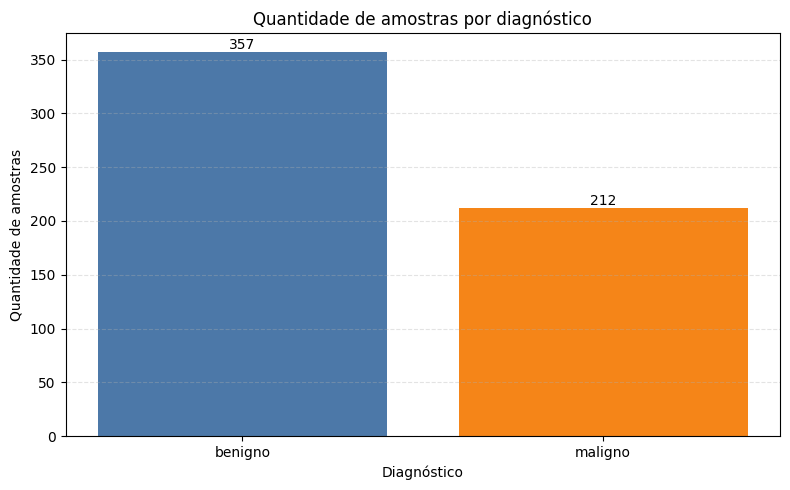

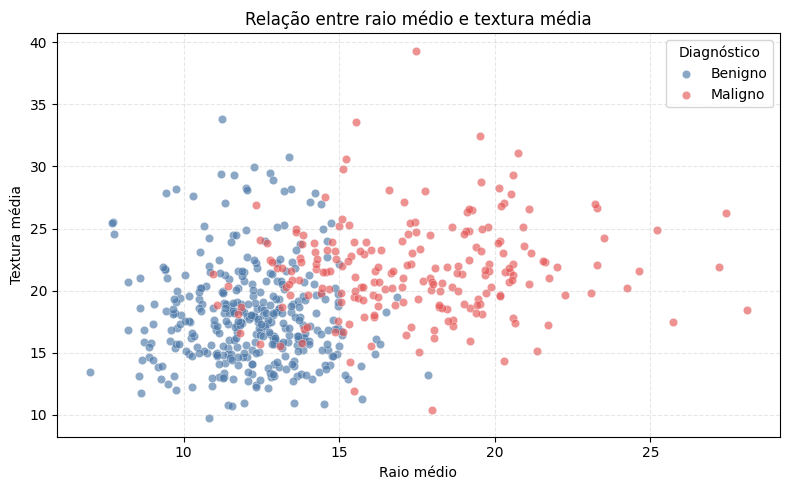

In [3]:
# Gráfico 1: quantidade de registros por diagnóstico
contagem = dados["diagnostico"].value_counts()

plt.figure(figsize=(8, 5))
barras = plt.bar(contagem.index, contagem.values,
                 color=["#4C78A8", "#F58518"])
plt.title("Quantidade de amostras por diagnóstico")
plt.xlabel("Diagnóstico")
plt.ylabel("Quantidade de amostras")
plt.grid(axis="y", linestyle="--", alpha=0.35)

for barra in barras:
    plt.text(barra.get_x() + barra.get_width() / 2,
             barra.get_height(),
             f"{int(barra.get_height())}",
             ha="center", va="bottom")

plt.tight_layout()
plt.show()

# Gráfico 2: relação entre raio médio e textura média
cores = dados["diagnostico"].map({
    "benigno": "#4C78A8",
    "maligno": "#E45756"
})

plt.figure(figsize=(8, 5))
for diagnostico, cor in [("benigno", "#4C78A8"), ("maligno", "#E45756")]:
    grupo = dados[dados["diagnostico"] == diagnostico]
    plt.scatter(grupo["mean radius"], grupo["mean texture"],
                label=diagnostico.capitalize(), color=cor,
                alpha=0.65, edgecolors="white", linewidths=0.3)

plt.title("Relação entre raio médio e textura média")
plt.xlabel("Raio médio")
plt.ylabel("Textura média")
plt.legend(title="Diagnóstico")
plt.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()


### **Entrega**: Envie o script (ou notebook do Colab) e a base no repositório da turma.
Padrão de nomenclatura: seunome_sobrenome_trabalho_bimestral.ipynb e seunome_sobrenome_nomedabase.csv."